In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (roc_curve, roc_auc_score,
                            precision_recall_curve, f1_score,
                            confusion_matrix, accuracy_score, ConfusionMatrixDisplay,
                            classification_report)
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("../data/data_mlp_dt.csv")

In [3]:
# train test split 
X = df.drop(columns=['IS_DELAYED'])
y = df['IS_DELAYED']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y   # 70% train
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp  # 15% val, 15% test
)

In [4]:
# Separate numeric and categorical columns
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# --- SCALE NUMERIC FEATURES ---
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[num_cols])
X_val_num   = scaler.transform(X_val[num_cols])
X_test_num  = scaler.transform(X_test[num_cols])

# --- ENCODE CATEGORICAL FEATURES ---
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_val_cat   = encoder.transform(X_val[cat_cols])
X_test_cat  = encoder.transform(X_test[cat_cols])

cat_feature_names = encoder.get_feature_names_out(cat_cols)

# --- COMBINE SCALED NUMERIC + ENC ODED CATEGORICAL ---
X_train_final = np.hstack([X_train_num, X_train_cat])
X_val_final   = np.hstack([X_val_num,   X_val_cat])
X_test_final  = np.hstack([X_test_num,  X_test_cat])

print("Train:", X_train_final.shape)
print("Val:",   X_val_final.shape)
print("Test:",  X_test_final.shape)

feature_names = list(num_cols) + list(cat_feature_names)
print(len(feature_names))


Train: (815661, 749)
Val: (174785, 749)
Test: (174785, 749)
749


In [5]:
X_train_t = torch.tensor(X_train_final, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)

X_val_t = torch.tensor(X_val_final, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)

X_test_t = torch.tensor(X_test_final, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)


train_dl = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=4096, shuffle=True)
val_dl   = DataLoader(TensorDataset(X_val_t,   y_val_t),   batch_size=4096)

In [6]:
class FlightDelayNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 1)
        )
    def forward(self, x):
        return self.net(x)


model = FlightDelayNN(X_train_final.shape[1])

In [7]:
pos_weight = torch.tensor([4.0], dtype=torch.float32)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [8]:
EPOCHS = 20

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []  

    for xb, yb in train_dl:
        logits = model(xb).squeeze()
        loss = criterion(logits, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # record *batch* loss
        batch_losses.append(loss.item())

    # record average loss for this epoch
    train_losses.append(np.mean(batch_losses))

    # Training accuracy 
    model.eval()
    train_correct = 0
    train_total = 0
    with torch.no_grad():
        for xb, yb in train_dl:
            logits = model(xb).squeeze()
            probs = torch.sigmoid(logits)
            pred = (probs > 0.6).float()

            train_correct += (pred == yb).sum().item()
            train_total += yb.size(0)

    train_acc = train_correct / train_total
    train_accuracies.append(train_acc)

    # Validation
    model.eval()
    val_batch_losses = []
    correct = 0
    total = 0

    with torch.no_grad():
        for xb, yb in val_dl:  
            logits = model(xb).squeeze()
            loss = criterion(logits, yb)
            val_batch_losses.append(loss.item())

            probs = torch.sigmoid(logits)
            pred = (probs > 0.6).float()

            correct += (pred == yb).sum().item()
            total += yb.size(0)

    val_loss = np.mean(val_batch_losses)
    val_acc = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | train_loss={train_losses[-1]:.4f} | train_accuracy={train_acc:.4f} val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")


Epoch 1 | train_loss=0.9111 | train_accuracy=0.8709 val_loss=0.6919 | val_acc=0.8690
Epoch 2 | train_loss=0.6541 | train_accuracy=0.8920 val_loss=0.6112 | val_acc=0.8890
Epoch 3 | train_loss=0.6059 | train_accuracy=0.8812 val_loss=0.5964 | val_acc=0.8761
Epoch 4 | train_loss=0.5857 | train_accuracy=0.8909 val_loss=0.5719 | val_acc=0.8852
Epoch 5 | train_loss=0.5708 | train_accuracy=0.8979 val_loss=0.5675 | val_acc=0.8922
Epoch 6 | train_loss=0.5596 | train_accuracy=0.8902 val_loss=0.5585 | val_acc=0.8823
Epoch 7 | train_loss=0.5503 | train_accuracy=0.8999 val_loss=0.5543 | val_acc=0.8916
Epoch 8 | train_loss=0.5425 | train_accuracy=0.9012 val_loss=0.5473 | val_acc=0.8931
Epoch 9 | train_loss=0.5350 | train_accuracy=0.9066 val_loss=0.5432 | val_acc=0.8981
Epoch 10 | train_loss=0.5277 | train_accuracy=0.9027 val_loss=0.5361 | val_acc=0.8938
Epoch 11 | train_loss=0.5217 | train_accuracy=0.9021 val_loss=0.5352 | val_acc=0.8931
Epoch 12 | train_loss=0.5166 | train_accuracy=0.9057 val_loss=0

In [9]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test_t).squeeze()
    test_probs = torch.sigmoid(test_logits)
    test_pred = (test_probs > 0.6).float()

# Convert tensors to NumPy
probs_np = test_probs.numpy()
pred_np = test_pred.numpy()

print("ROC AUC:", roc_auc_score(y_test, probs_np))
print("F1 score:", f1_score(y_test, pred_np))
print("accuracy:", accuracy_score(y_test, pred_np))
print(classification_report(y_test, pred_np))


ROC AUC: 0.9325794756215096
F1 score: 0.7573298584374815
accuracy: 0.9062390937437423
              precision    recall  f1-score   support

           0       0.94      0.94      0.94    140658
           1       0.77      0.75      0.76     34127

    accuracy                           0.91    174785
   macro avg       0.85      0.85      0.85    174785
weighted avg       0.91      0.91      0.91    174785



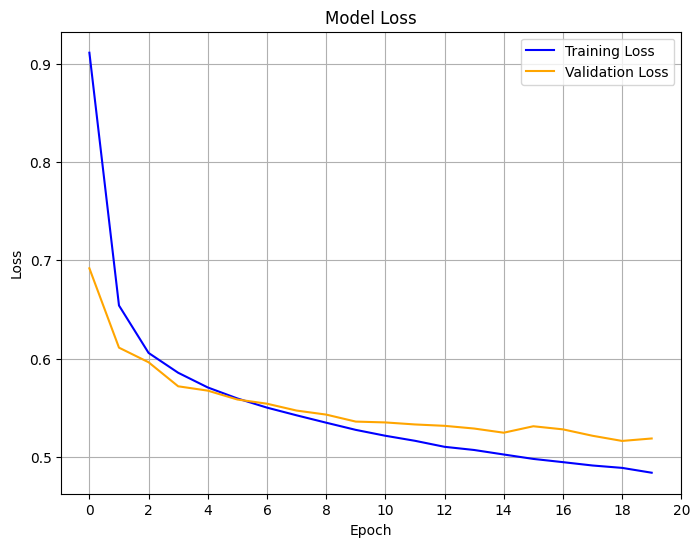

In [17]:
plt.figure(figsize=(8,6))

plt.plot(train_losses, label="Training Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="orange")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([0,2,4,6,8,10,12,14,16,18,20])
plt.title("Model Loss")
plt.grid(True)
plt.legend()

plt.show()

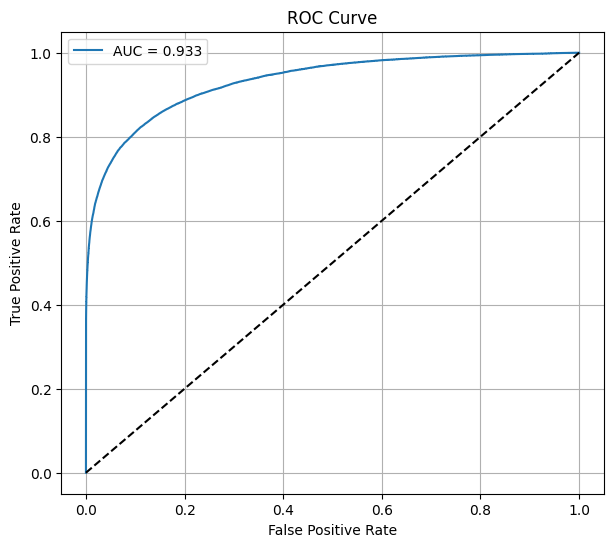

In [20]:
# roc curve
fpr, tpr, _ = roc_curve(y_test, test_probs)
auc = roc_auc_score(y_test, test_probs)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

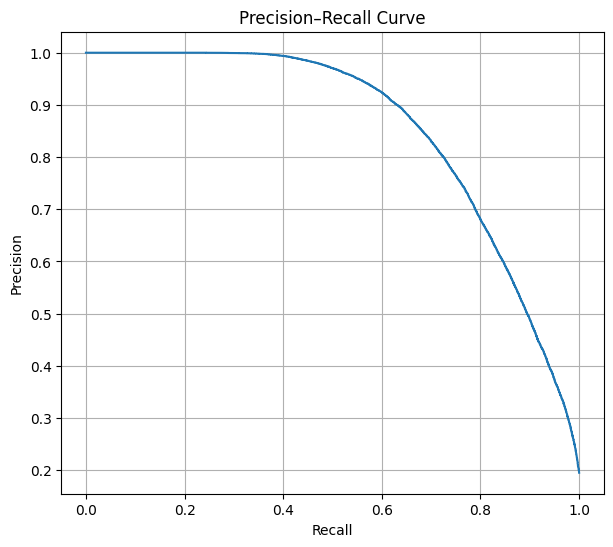

In [14]:
# precision-recall curve
precision, recall, _ = precision_recall_curve(y_test, test_probs)

plt.figure(figsize=(7,6))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.grid(True)
plt.show()

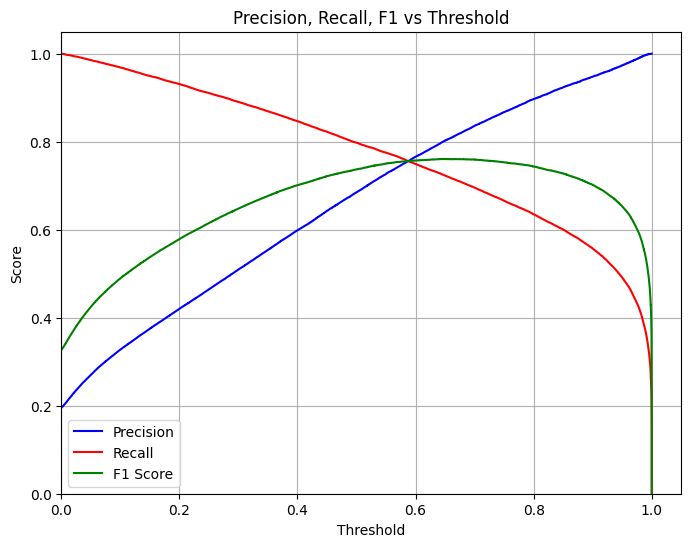

In [37]:
# PR curve
precision, recall, thresholds = precision_recall_curve(y_test, test_probs)

thresholds = np.concatenate(([0], thresholds)) # pad thresholds

# F1 curve
f1_scores = 2 * precision * recall / (precision + recall + 1e-12)

# ---- PLOT ----
plt.figure(figsize=(8,6))

plt.plot(thresholds, precision, label="Precision", color="blue")
plt.plot(thresholds, recall, label="Recall", color="red")
plt.plot(thresholds, f1_scores, label="F1 Score", color="green")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, F1 vs Threshold")
plt.grid(True)
plt.legend()
plt.xlim(0, 1.05)
plt.ylim(0, 1.05)
plt.show()


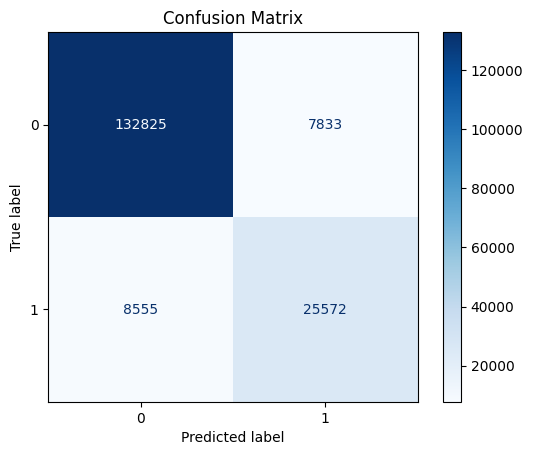

In [18]:
# confusion matrix
cm = confusion_matrix(y_test, test_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

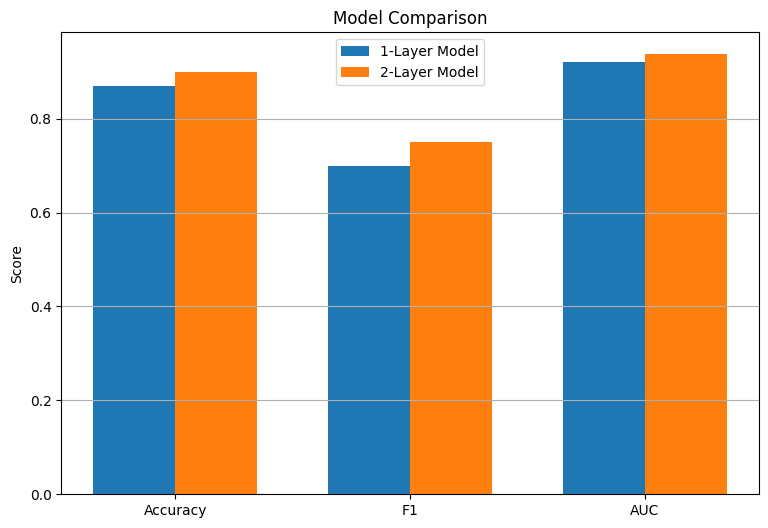

In [ ]:
# model comparison bar chart 
one_layer = {
    "Accuracy": 0.87,
    "F1": 0.70,
    "AUC": 0.92,
}

two_layer = {
    "Accuracy": 0.91,
    "F1": 0.75,
    "AUC": 0.93,
}

labels = list(one_layer.keys())
x = np.arange(len(labels))
w = 0.35

plt.figure(figsize=(9,6))
plt.bar(x - w/2, one_layer.values(), width=w, label="1-Layer Model")
plt.bar(x + w/2, two_layer.values(), width=w, label="2-Layer Model")
plt.xticks(x, labels)
plt.ylabel("Score")
plt.title("Model Comparison")
plt.legend()
plt.grid(True, axis='y')
plt.show()


Baseline F1: 0.7573298584374815


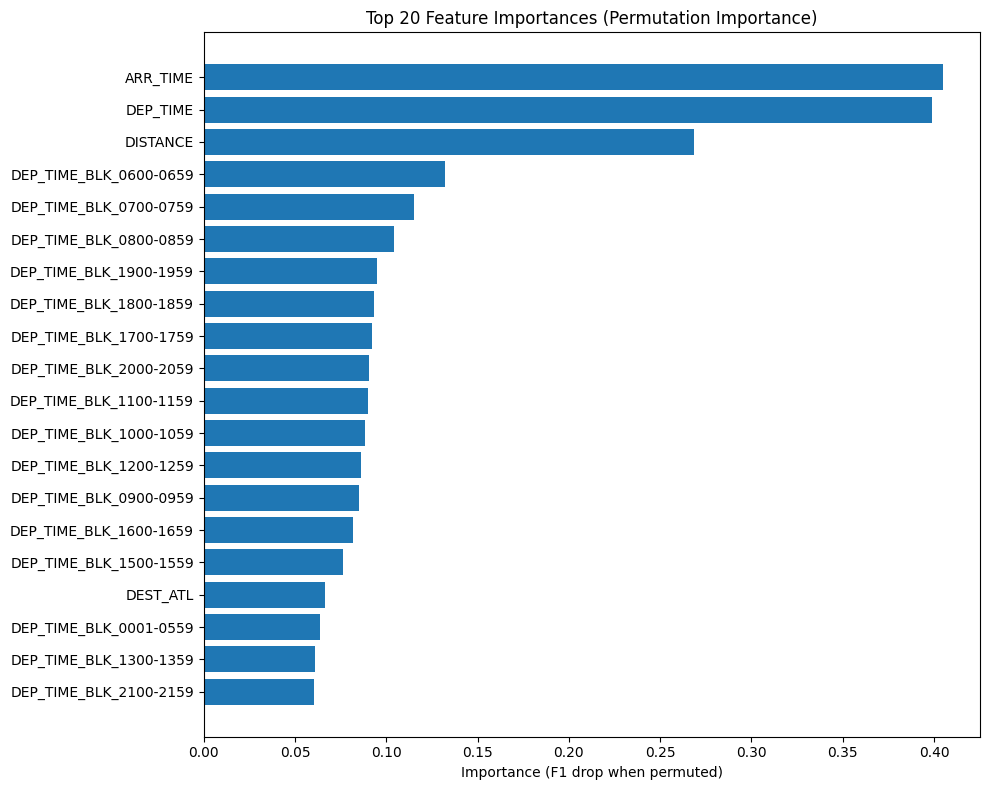

In [ ]:
# 1. Function to compute F1 score with threshold=0.6
def compute_f1(model, X, y, threshold=0.6):
    model.eval()
    with torch.no_grad():
        logits = model(X).squeeze()
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs > threshold).astype(int)
        return f1_score(y, preds)

# Convert test tensor back to NumPy for permutation
X_test_np = X_test_t.cpu().numpy()
y_test_np = y_test.values

# Compute baseline F1 score
baseline_f1 = compute_f1(model, X_test_t, y_test_np)
print("Baseline F1:", baseline_f1)

# Permutation importance loop
feature_importance = []

for i in range(X_test_np.shape[1]):
    X_permuted = X_test_np.copy()
    np.random.shuffle(X_permuted[:, i])   # shuffle column i

    X_perm_t = torch.tensor(X_permuted, dtype=torch.float32)
    
    perm_f1 = compute_f1(model, X_perm_t, y_test_np)
    importance = baseline_f1 - perm_f1
    feature_importance.append(importance)

feature_importance = np.array(feature_importance)

# Plot top 20 important features
top_k = 20
indices = np.argsort(feature_importance)[-top_k:]   # top K

plt.figure(figsize=(10,8))
plt.barh(range(top_k), feature_importance[indices])
plt.yticks(range(top_k), np.array(feature_names)[indices])
plt.xlabel("Importance (F1 drop when permuted)")
plt.title("Top 20 Feature Importances (Permutation Importance)")
plt.tight_layout()
plt.show()
